# time-series modelling

In [4]:
%pip install yfinance pandas numpy matplotlib


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# configurations

In [6]:
tickers = ["SPY", "TLT", "GLD", "EEM", "IEF", "QQQ"]
start = "2005-01-01"
end = None  # None = today
lookbacks = [20, 60, 120, 252]
cost_bps = 2.0           # cost per 1.0 turnover unit
annualization = 252

# data

In [7]:
data = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=False)

# yfinance shape handling
if isinstance(data.columns, pd.MultiIndex):
    prices = data["Close"].copy()
else:
    prices = data.copy()

prices = prices.dropna(how="all").ffill()
rets = prices.pct_change()

print(f"Data range: {prices.index.min().date()} -> {prices.index.max().date()}")
print(f"Assets: {list(prices.columns)}")


Data range: 2005-01-03 -> 2026-03-05
Assets: ['EEM', 'GLD', 'IEF', 'QQQ', 'SPY', 'TLT']


# helpers

 ### max_drawdown
 - tells us the worst loss from a previous peak in the equity curve
 
- equity goes from 1.20 down to 0.90
- drawdown = 0.90 / 1.20 - 1.0 = -0.25 (25% loss)
-  if this is the biggest drop in the whole period, max drawdown is -25%
why it matters:
- measures how painful the strategy can get, even if final return is good

In [8]:
def max_drawdown(equity_curve: pd.Series) -> float:
    running_max = equity_curve.cummax() #cummax() is cumulative maximum
    dd = equity_curve / running_max - 1.0
    return dd.min()

### perf_stats
- takes a series of daily strategy returns and outputs key performance metrics

- total return: overall gain/loss for whole backtest 0.6 = +60% total 
- CAGR (compound annual growth rate): average yearly growth rate after compounding 0.08 = ~8% per year
- Vol (volatility): how much returns swing up/down (risk/instability) higher = bumpier ride
- Sharpe: Return per unit of volatility (risk-adjusted return).
Higher is better. >1 descent, >2 strong (context matters)
- Max Drawdown: worst drop from a previous peak
- Hit Rate: fraction of days with positive return 0.53 = 53% of days positive


In [9]:
def perf_stats(net_ret: pd.Series, ann=252) -> dict:
    net_ret = net_ret.dropna()
    if len(net_ret) == 0:
        return {}

    eq = (1 + net_ret).cumprod()
    total_return = eq.iloc[-1] - 1.0
    years = len(net_ret) / ann
    cagr = (eq.iloc[-1] ** (1 / years) - 1) if years > 0 else np.nan
    vol = net_ret.std() * np.sqrt(ann)
    sharpe = (net_ret.mean() / net_ret.std()) * np.sqrt(ann) if net_ret.std() > 0 else np.nan
    mdd = max_drawdown(eq)
    hit_rate = (net_ret > 0).mean()

    return {
        "Total Return": total_return,
        "CAGR": cagr,
        "Vol": vol,
        "Sharpe": sharpe,
        "Max Drawdown": mdd,
        "Hit Rate": hit_rate,
    }

### run_tsmom
- this function runs the full time-series momentum backtest for one lookback window

In [10]:
def run_tsmom(prices: pd.DataFrame, lookback: int, cost_bps=2.0):
    rets = prices.pct_change()

    # Signal at t from lookback return
    signal = np.sign(prices / prices.shift(lookback) - 1.0)

    # Trade at t+1 to avoid lookahead
    position = signal.shift(1)

    # Equal weight across available assets each day
    gross_ret = (position * rets).mean(axis=1)

    # Turnover proxy
    turnover = position.diff().abs().mean(axis=1).fillna(0.0)

    # Costs
    net_ret = gross_ret - (cost_bps / 10000.0) * turnover
    net_ret = net_ret.fillna(0.0)

    equity = (1.0 + net_ret).cumprod()
    drawdown = equity / equity.cummax() - 1.0

    return {
        "signal": signal,
        "position": position,
        "gross_ret": gross_ret,
        "turnover": turnover,
        "net_ret": net_ret,
        "equity": equity,
        "drawdown": drawdown,
    }

# run multiple lookbacks
### lookback
- how far back in time you compare price to generate the signal

- lookback = 60 means compare today's price vs price 60 trading days ago
- small lookback(20): react faster, noisier
- large lookback (252): slower, smoother, more lagged

### 'best' lookback?
Short answer: you can’t know a single “best” lookback in advance. You choose a robust one.

Use this process:

1. Split data into periods
- Train: older years
- Test: newer years (unseen)
2. Try a range (example)
- 20, 40, 60, 120, 180, 252
3. Evaluate on test period using multiple metrics
- Sharpe, Max Drawdown, CAGR, Turnover (cost impact)
4. Pick lookbacks that are stable, not just top 1
- If 60 is best but 50 and 70 are bad, that is fragile.
- Prefer regions where nearby values perform similarly.
5. Re-check with walk-forward
- Refit on rolling windows, test on next window.
6. Better: combine lookbacks
- Average signals from multiple lookbacks (e.g. 20/60/120/252) to reduce overfitting.

For your level now: don’t hunt one magic number. Start with 60 and compare against 20/120/252; prefer the one with decent return + lower drawdown + reasonable turnover.

In [11]:
results = {}
rows = []

for lb in lookbacks:
    out = run_tsmom(prices, lookback=lb, cost_bps=cost_bps)
    stats = perf_stats(out["net_ret"], ann=annualization)
    stats["Avg Turnover (daily)"] = out["turnover"].mean()
    stats["Lookback"] = lb
    rows.append(stats)
    results[lb] = out

stats_df = pd.DataFrame(rows).set_index("Lookback")
stats_df = stats_df[
    ["Total Return", "CAGR", "Vol", "Sharpe", "Max Drawdown", "Hit Rate", "Avg Turnover (daily)"]
]
print("\nPerformance Summary (net of costs):")
print((stats_df * pd.Series({
    "Total Return": 100, "CAGR": 100, "Vol": 100, "Sharpe": 1, "Max Drawdown": 100, "Hit Rate": 100, "Avg Turnover (daily)": 1
})).round(2))


Performance Summary (net of costs):
          Total Return  CAGR    Vol  Sharpe  Max Drawdown  Hit Rate  \
Lookback                                                              
20               19.54  0.85  11.59    0.13        -23.41     51.13   
60               74.94  2.68  11.30    0.29        -29.95     52.65   
120             139.30  4.21  11.21    0.42        -19.87     52.53   
252              80.56  2.84  10.66    0.32        -31.42     51.95   

          Avg Turnover (daily)  
Lookback                        
20                        0.19  
60                        0.10  
120                       0.06  
252                       0.04  


# plot equity curves

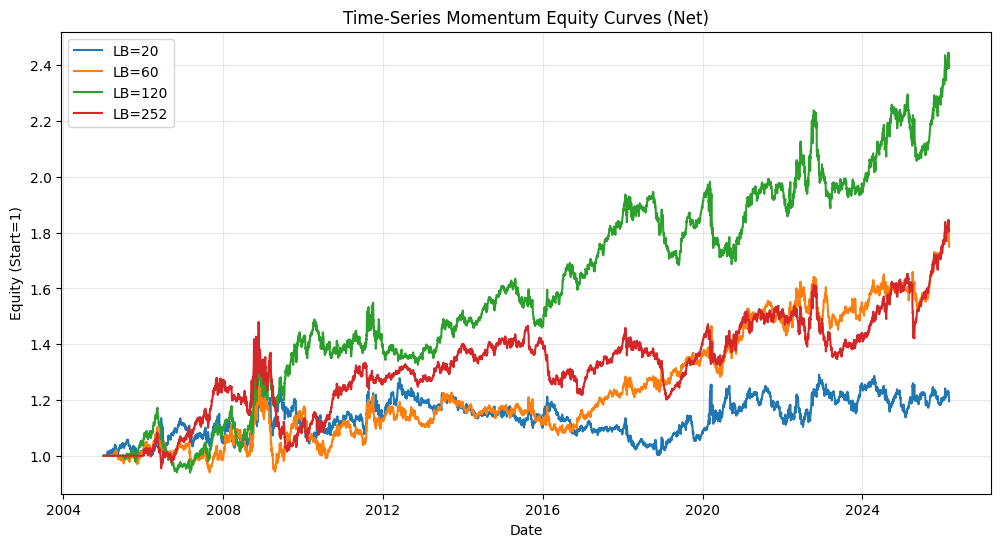

In [12]:
plt.figure(figsize=(12, 6))
for lb in lookbacks:
    plt.plot(results[lb]["equity"], label=f"LB={lb}")
plt.title("Time-Series Momentum Equity Curves (Net)")
plt.ylabel("Equity (Start=1)")
plt.xlabel("Date")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# plot drawdowns

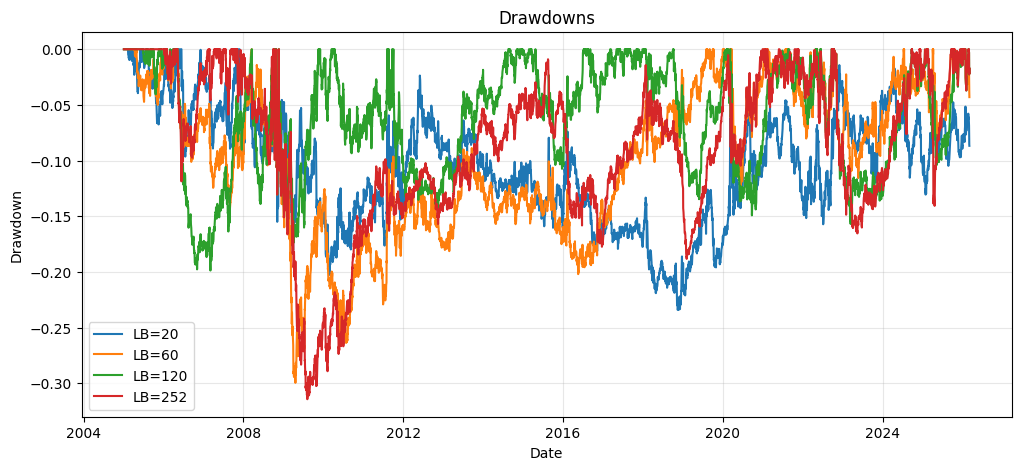

In [13]:
plt.figure(figsize=(12, 5))
for lb in lookbacks:
    plt.plot(results[lb]["drawdown"], label=f"LB={lb}")
plt.title("Drawdowns")
plt.ylabel("Drawdown")
plt.xlabel("Date")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# benchmark vs SPY buy-and-hold 

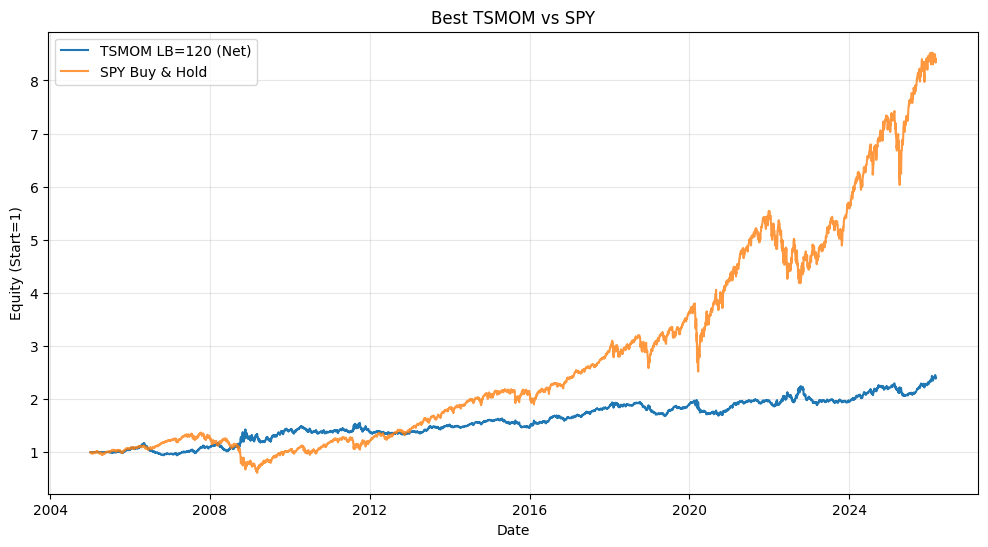


Best lookback by Sharpe: 120


In [14]:
spy_ret = prices["SPY"].pct_change().fillna(0.0)
spy_eq = (1 + spy_ret).cumprod()

best_lb = stats_df["Sharpe"].idxmax()
best_eq = results[best_lb]["equity"]

plt.figure(figsize=(12, 6))
plt.plot(best_eq, label=f"TSMOM LB={best_lb} (Net)")
plt.plot(spy_eq, label="SPY Buy & Hold", alpha=0.8)
plt.title("Best TSMOM vs SPY")
plt.ylabel("Equity (Start=1)")
plt.xlabel("Date")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"\nBest lookback by Sharpe: {best_lb}")

     TS Final  BH Final  TS CAGR %  BH CAGR %  TS Sharpe  BH Sharpe  TS MDD %  \
SPY      2.16      8.40       3.71      10.59       0.29       0.62    -28.40   
GLD      1.98     10.86       3.29      11.95       0.27       0.72    -54.26   
TLT      1.21      1.98       0.89       3.28       0.13       0.29    -36.95   
QQQ      1.17     18.16       0.74      14.70       0.14       0.74    -43.97   
IEF      1.06      1.99       0.27       3.30       0.07       0.51    -26.01   
EEM      1.01      4.00       0.06       6.78       0.14       0.38    -73.77   

     BH MDD %  
SPY    -55.19  
GLD    -45.56  
TLT    -48.35  
QQQ    -53.40  
IEF    -23.92  
EEM    -66.43  


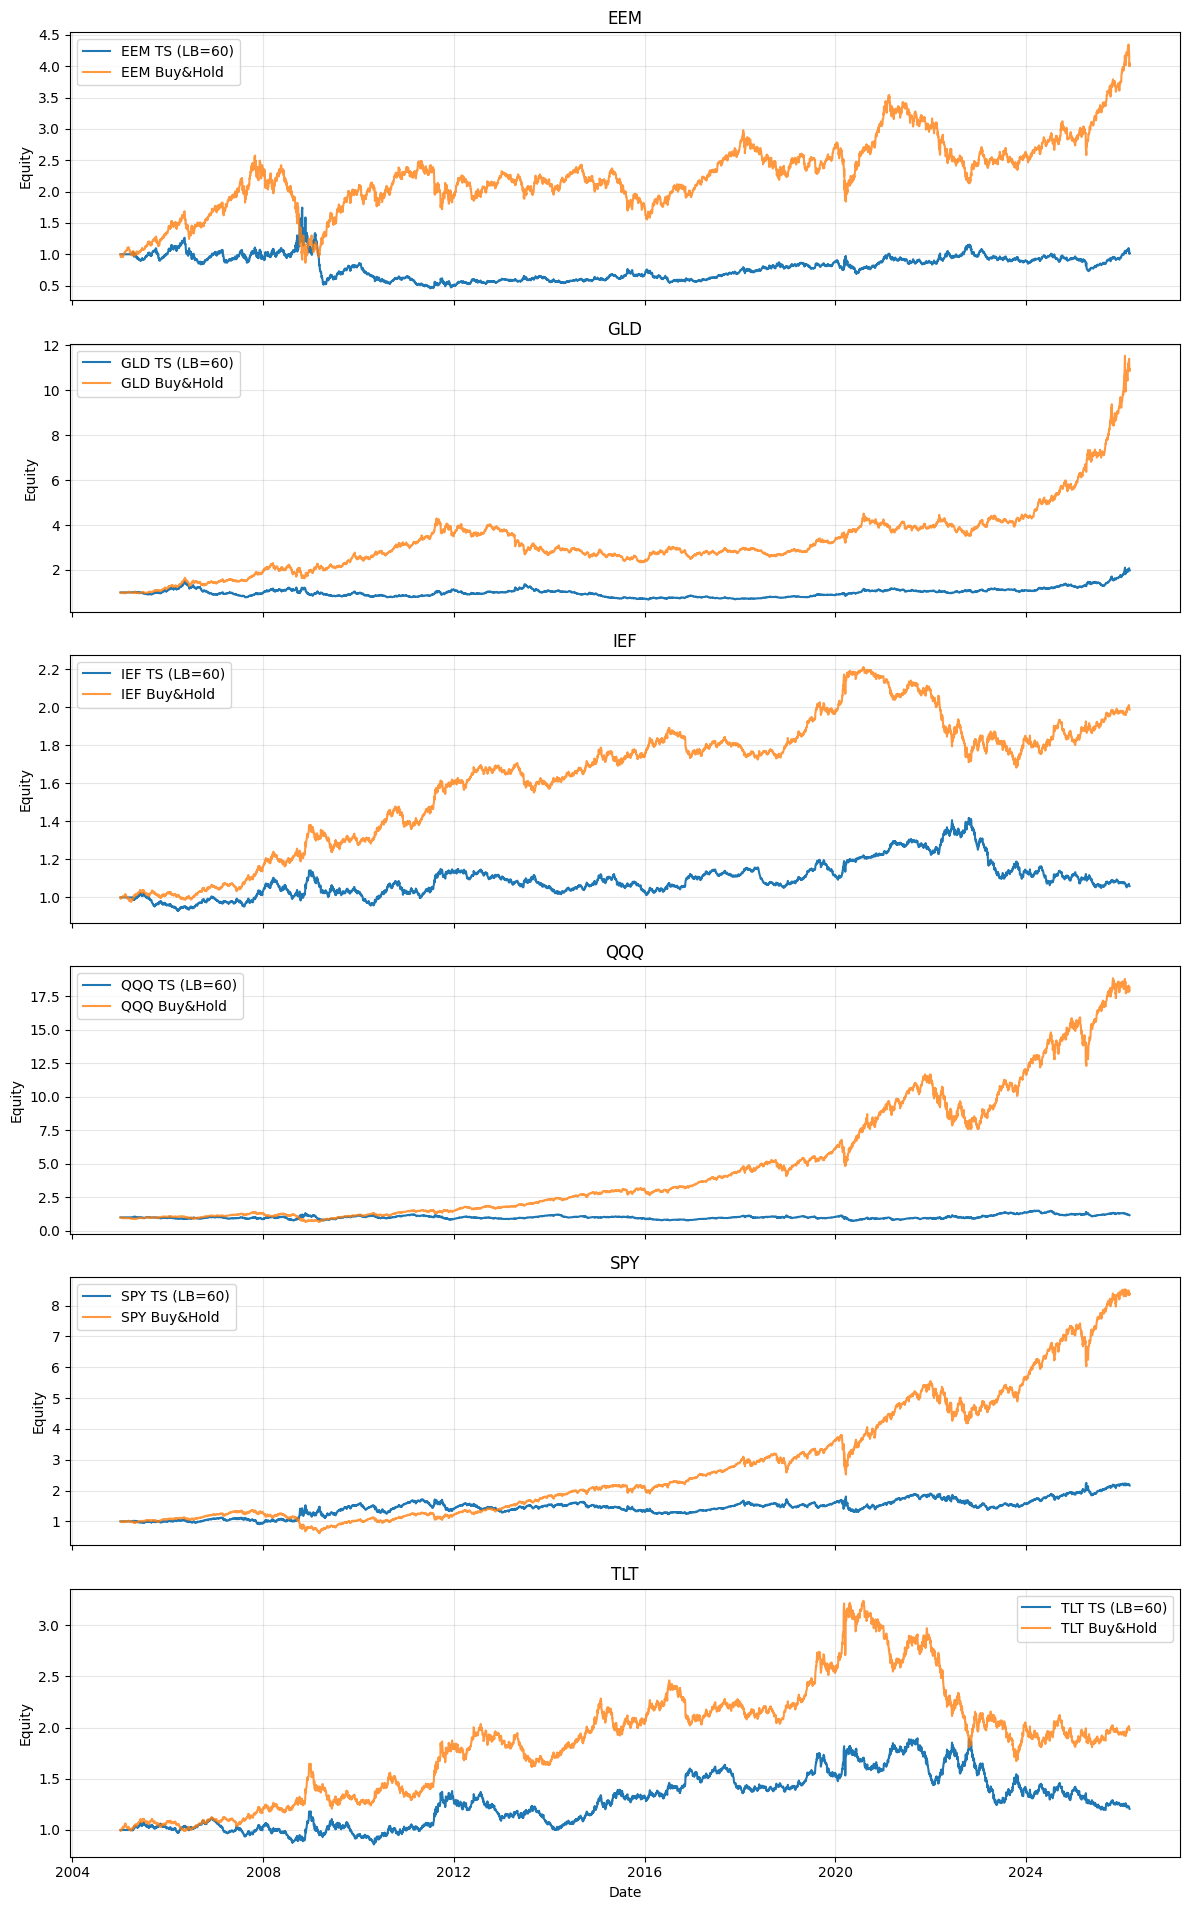

In [15]:
# Compare per-asset TS Momentum vs Buy & Hold
lookback = 60
rows = {}
equity_curves = {}

for ticker in prices.columns:
    p = prices[ticker].dropna()
    r = p.pct_change().fillna(0.0)

    # TS momentum (single asset)
    signal = pd.Series(np.sign(p / p.shift(lookback) - 1.0), index=p.index)
    position = signal.shift(1).fillna(0.0)
    gross_ret = (position * r)
    turnover = position.diff().abs().fillna(0.0)
    net_ret = gross_ret - (cost_bps / 10000.0) * turnover
    ts_eq = (1.0 + net_ret).cumprod()

    # Buy & hold
    bh_ret = r
    bh_eq = (1.0 + bh_ret).cumprod()

    # Stats (reusing your perf_stats function)
    ts_stats = perf_stats(net_ret, ann=annualization)
    bh_stats = perf_stats(bh_ret, ann=annualization)

    rows[ticker] = {
        "TS Final": ts_eq.iloc[-1],
        "BH Final": bh_eq.iloc[-1],
        "TS CAGR %": ts_stats["CAGR"] * 100,
        "BH CAGR %": bh_stats["CAGR"] * 100,
        "TS Sharpe": ts_stats["Sharpe"],
        "BH Sharpe": bh_stats["Sharpe"],
        "TS MDD %": ts_stats["Max Drawdown"] * 100,
        "BH MDD %": bh_stats["Max Drawdown"] * 100,
    }

    equity_curves[ticker] = (ts_eq, bh_eq)

compare_df = pd.DataFrame(rows).T.sort_values("TS Final", ascending=False)
print(compare_df.round(2))

# Plot each asset: TS vs BH
n = len(prices.columns)
fig, axes = plt.subplots(n, 1, figsize=(12, 3.2 * n), sharex=True)
if n == 1:
    axes = [axes]

for ax, ticker in zip(axes, prices.columns):
    ts_eq, bh_eq = equity_curves[ticker]
    ax.plot(ts_eq, label=f"{ticker} TS (LB={lookback})")
    ax.plot(bh_eq, label=f"{ticker} Buy&Hold", alpha=0.8)
    ax.set_title(ticker)
    ax.set_ylabel("Equity")
    ax.grid(alpha=0.3)
    ax.legend()

plt.xlabel("Date")
plt.tight_layout()
plt.show()
